In [1]:
#####     Model Bias Cross-Validation     #####
from pathlib import Path
from string import ascii_lowercase
import warnings

import numpy as np
import pandas as pd
from joblib import load, dump
import rasterio

import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF
from statsmodels.nonparametric.smoothers_lowess import lowess

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

RANDOM_SEED = 42  # 随机数种子

OUT_DIR = ROOT = Path("./")
OUT_DIR.mkdir(parents=True, exist_ok=True)

lat, lon = np.arange(-90, 90.1, 1), np.arange(0, 360.1, 1)


def flipImage(tiff: np.ndarray, shift=180) -> np.ndarray:
    """Flip latitude and shift longitude from original raster layout to 0-360° layout."""
    flipped = np.flip(tiff, axis=0)  # 纬度翻转
    shifted = np.roll(flipped, -shift, axis=1)  # 经度平移
    return shifted

def CheckVIF(data: np.ndarray, names: list[str], vif_thr: float = 10., protected: list[str] = []):
    """Iteratively remove the non-protected variable with the largest VIF if it exceeds threshold."""
    # Calculate VIF
    X = sm.add_constant(data)
    vifs = np.array([VIF(X, i) for i in range(1, X.shape[1])])
    # Filter out protected variables
    protected = [] if protected is None else protected
    for p in protected:
        if not p in names:  print(f" > Warning: Variable {p} not found!")
    not_removable = np.array([(name in protected) for name in names])
    vifs[not_removable] = -np.inf
    # Remove the variable with the largest VIF
    max_vif, idx = np.max(vifs), np.argmax(vifs)
    if max_vif < vif_thr:
        print(f"END. Remain Vars: {len(names)}")
        return True, data, names
    print(f"Var {names[idx]} eliminated. VIF: {max_vif:.2f}")
    return False, np.delete(data, idx, axis=1), np.delete(names, idx, axis=0).tolist()

def LinearRegTest(X: np.ndarray, Y: np.ndarray):
    print("Linear Regression")
    model = LinearRegression()
    model.fit(X, Y)
    r2 = model.score(X, Y)
    rmse = np.sqrt(np.mean((model.predict(X) - Y)**2))
    print(f"R2 = {r2:.4f},  RMSE = {rmse:.4f}")

def panel_label(ax, label: str):
    """Add label to subplot."""
    label = f"({label})"
    ax.text(0.02, 0.97, label, transform=ax.transAxes, ha="left", va="top",
            fontsize=12, fontweight="bold", zorder=10,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.5, pad=1.0))

In [2]:
### ----- Load ESACCI V7 / CMIP6 / Koppen / clusters ----- ###
ESAv7_data = np.load(ROOT / "Data" / "AGBC_ESAv7.npz")
ESAv7_std = np.load(ROOT / "Data" / "AGBCsd_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(v.astype(np.float32)) for k, v in ESAv7_data.items()}
ESAv7_std = {k.title(): flipImage(v.astype(np.float32)) for k, v in ESAv7_std.items()}
ESA_data = ESAv7_data["Mean"].copy()
ESA_std = ESAv7_std["Mean"].copy()

CMIP_set = np.load(ROOT / "Data" / "CMIP6_AGBC.npz")
modelNames = list(CMIP_set.keys())
CMIP_data = np.stack([np.array(CMIP_set[name], dtype=np.float32) for name in modelNames], axis=0)
modelNum = len(modelNames)
print(f"CMIP Models: {modelNum}")

with rasterio.open(ROOT / "Data" / "Koppen_2010.tif", "r") as src:
    Koppen = flipImage(src.read(1).astype(np.float32))

ValidMask = (Koppen > 0) & (ESA_data > 0)
TreeMask = load(ROOT / "Data" / "Masks" / "treemask.joblib").astype(bool)
TreeMask &= ValidMask
ESA_datat = ESA_data.copy()
ESA_datat[~TreeMask] = np.nan
CMIP_datat = CMIP_data.copy()
CMIP_datat[:, ~TreeMask] = np.nan

cluster_df = pd.read_csv(ROOT / "cluster.csv", header=0)
cluster_df["Cluster"] = cluster_df["Cluster"].astype(int)
cluster_map = cluster_df.set_index("Model")["Cluster"].to_dict()
cluster_ids = sorted(cluster_df["Cluster"].unique())

missing = sorted(set(modelNames) - set(cluster_map))
if missing:
    raise ValueError(f"Models missing from `cluster.csv`: {missing}")

model_groups = {"MME Mean": modelNames}
for cid in cluster_ids:
    model_groups[f"Cluster {cid}"] = cluster_df.loc[cluster_df["Cluster"] == cid, "Model"].tolist()

for label, names in model_groups.items():
    print(f"{label}: N={len(names)}")


CMIP Models: 30
MME Mean: N=30
Cluster 1: N=15
Cluster 2: N=5
Cluster 3: N=8
Cluster 4: N=2


In [3]:
### ----- Load explanatory variables ----- ###
clim_name = [
    "Tmean", "MDR", "ISO", "Tssn", "Tmax", "Tmin", "TAR", "TWeQ", "TDrQ", "TWaQ", "TCoQ",
    "Prec", "PWM", "PDM", "Pssn", "PWeQ", "PDrQ", "PWaQ", "PCoQ",
]
var_clim = load(ROOT / "Data" / "Vars" / "VarClim.joblib")
var_soil1 = load(ROOT / "Data" / "Vars" / "VarSoil_face.joblib")
var_soil2 = load(ROOT / "Data" / "Vars" / "VarSoil_sub.joblib")
var_veg = load(ROOT / "Data" / "Vars" / "VarVeg.joblib")

vars_list, vars_name, vars_group = [], [], []
for key, val in var_clim.items():
    idx = len(vars_list)
    vars_list.append(val.astype(np.float32))
    vars_name.append(f"{key} ({clim_name[idx]})")
    vars_group.append("Climate")
for key, val in var_soil1.items():
    vars_list.append(val.astype(np.float32))
    vars_name.append(key.replace("_face", "_top"))  # Rename topsoil variables
    vars_group.append("Soil")
for key, val in var_soil2.items():
    vars_list.append(val.astype(np.float32))
    vars_name.append(key)
    vars_group.append("Soil")
for key, val in var_veg.items():
    vars_list.append(val.astype(np.float32))
    vars_name.append(key)
    vars_group.append("Vegetation")

num_clim = sum(g == "Climate" for g in vars_group)
num_soil = sum(g == "Soil" for g in vars_group)
num_veg = sum(g == "Vegetation" for g in vars_group)
Variables_all = np.stack(vars_list, axis=0)  # (V, lat, lon)
print(f"Variables: {len(vars_name)}")
print(f"Clim: {num_clim},  Soil: {num_soil},  Veg: {num_veg}")

### ----- VIF filtering ----- ###
RUN_VIF = True
selected = vars_name.copy()
selected_group = vars_group.copy()
Variables_selected = Variables_all.copy()

if RUN_VIF:
    print("\nVariance Inflation Factor (VIF) Check")
    protected = ["bio_1 (Tmean)", "bio_12 (Prec)"]
    mask0 = ValidMask & np.all(np.isfinite(Variables_all), axis=0)
    X_vif = Variables_all[:, mask0].T
    selected = vars_name.copy()
    for iters in range(len(vars_name)):
        print(f"Iter {iters+1}:", end=" ")
        passed, X_vif, selected = CheckVIF(X_vif, selected, protected=protected)
        if passed: break
    keep_idx = [vars_name.index(name) for name in selected]
    Variables_selected = Variables_all[keep_idx]
    selected_group = [vars_group[i] for i in keep_idx]

color_type = {"Climate": "deepskyblue", "Soil": "goldenrod", "Vegetation": "forestgreen"}
feature_colors = [color_type[g] for g in selected_group]
print(f"\nSelected variables: {len(selected)}")
print(np.array(selected))


Variables: 48
Clim: 19,  Soil: 26,  Veg: 3

Variance Inflation Factor (VIF) Check
Iter 1: Var bio_6 (Tmin) eliminated. VIF: 257348550135456.91
Iter 2: Var sand_top eliminated. VIF: 312668.49
Iter 3: Var sand_sub eliminated. VIF: 260081.63
Iter 4: Var bio_11 (TCoQ) eliminated. VIF: 9212.49
Iter 5: Var bio_4 (Tssn) eliminated. VIF: 1030.88
Iter 6: Var bio_10 (TWaQ) eliminated. VIF: 330.79
Iter 7: Var bio_17 (PDrQ) eliminated. VIF: 186.68
Iter 8: Var bio_7 (TAR) eliminated. VIF: 178.83
Iter 9: Var bio_16 (PWeQ) eliminated. VIF: 147.51
Iter 10: Var silt_sub eliminated. VIF: 47.43
Iter 11: Var bio_9 (TDrQ) eliminated. VIF: 39.36
Iter 12: Var clay_sub eliminated. VIF: 35.79
Iter 13: Var phh2o_top eliminated. VIF: 31.26
Iter 14: Var wv0010_top eliminated. VIF: 29.93
Iter 15: Var soc_top eliminated. VIF: 29.27
Iter 16: Var cec_top eliminated. VIF: 22.01
Iter 17: Var bio_13 (PWM) eliminated. VIF: 20.21
Iter 18: Var cfvo_sub eliminated. VIF: 18.76
Iter 19: Var bio_5 (Tmax) eliminated. VIF: 18.46

In [4]:
warnings.filterwarnings("ignore")

### ----- Hyperparameter tuning on MME Mean with ordinary and spatial cross-validation ----- ###
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import r2_score, mean_squared_error

Ordinary_CV_Search_Path = OUT_DIR / "RF_Ordinary_CV_Search.csv"
Spatial_CV_Search_Path = OUT_DIR / "RF_Spatial_CV_Search.csv"
CV_Result_Path = OUT_DIR / "RF_CV_Result.csv"

BASE_RF_KWARGS = dict(random_state=RANDOM_SEED)
PARAM_GRID = {
    "n_estimators": [100, 150, 200],
    "min_samples_split": [2, 4, 8],
    "max_features": [0.6, 0.8, 1.0],
}

CV_FOLDS = 10  # 交叉验证折数
Lat_Sep, Lon_Sep = 10, 20  # 空间分块大小（deg）
print(f"CV Folds: {CV_FOLDS};  Spatial Block: {Lat_Sep}x{Lon_Sep} deg")

def build_group_xy(names: list[str]) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    idx = [modelNames.index(name) for name in names]
    cmip_mean = np.nanmean(CMIP_datat[idx], axis=0)
    bias = cmip_mean - ESA_datat
    mask = TreeMask & np.isfinite(bias) & np.all(np.isfinite(Variables_selected), axis=0)
    X = Variables_selected[:, mask].T.astype(np.float32)
    Y = bias[mask].astype(np.float32)
    return X, Y, bias.astype(np.float32), mask


def get_mask_coordinates(mask: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return pixel-center latitude and longitude for valid mask pixels."""
    lat_center = (lat[:-1] + lat[1:]) / 2
    lon_center = (lon[:-1] + lon[1:]) / 2
    lat_grid, lon_grid = np.meshgrid(lat_center, lon_center, indexing="ij")
    return lat_grid[mask], lon_grid[mask]


def make_spatial_block_groups(lat_vec: np.ndarray, lon_vec: np.ndarray) -> np.ndarray:
    """Randomly assign spatial blocks to K folds."""
    lat_block = np.floor((lat_vec + 90) / Lat_Sep).astype(int)
    lon_block = np.floor(lon_vec / Lon_Sep).astype(int)
    block_id = lat_block * 100 + lon_block
    # Randomize at the block level so pixels from one block always remain together.
    # Cyclic allocation after shuffling keeps the number of blocks per fold balanced.
    unique_blocks = np.asarray(sorted(np.unique(block_id)))
    print(block_id.shape, unique_blocks.shape)
    rng = np.random.default_rng(RANDOM_SEED)
    rng.shuffle(unique_blocks)
    block_to_fold = {block: i % CV_FOLDS for i, block in enumerate(unique_blocks)}
    return np.array([block_to_fold[block] for block in block_id], dtype=int)


def make_latitude_groups(lat_vec: np.ndarray) -> np.ndarray:
    """Use each latitude band as one validation block."""
    sep = Lat_Sep
    return np.floor((lat_vec + 90) / sep).astype(int)


def make_longitude_groups(lon_vec: np.ndarray) -> np.ndarray:
    """Use each longitude band as one validation block."""
    sep = Lon_Sep
    return np.floor(lon_vec / sep).astype(int)


def make_group_splits(groups: np.ndarray):
    """Create leave-one-group-out splits from precomputed fold or block labels."""
    for group in sorted(np.unique(groups)):
        test_idx = np.where(groups == group)[0]
        train_idx = np.where(groups != group)[0]
        if len(test_idx) == 0 or len(train_idx) == 0:
            continue
        yield train_idx, test_idx


def collect_grid_best_folds(grid: GridSearchCV, best_idx: int,
                            splits: list[tuple[np.ndarray, np.ndarray]],
                            method: str) -> pd.DataFrame:
    """Collect validation metrics and pixel counts for each CV fold."""
    rows = []
    for i, (train_idx, test_idx) in enumerate(splits):
        rows.append({
            "method": method,
            "block": i + 1,
            "n_train": int(len(train_idx)),
            "n_test": int(len(test_idx)),
            "R2": grid.cv_results_[f"split{i}_test_R2"][best_idx],
            "RMSE": -grid.cv_results_[f"split{i}_test_RMSE"][best_idx],
        })
    return pd.DataFrame(rows)


def evaluate_split_cv(method: str, X: np.ndarray, Y: np.ndarray,
                      splits: list[tuple[np.ndarray, np.ndarray]],
                      params: dict) -> pd.DataFrame:
    """Evaluate one fixed RF parameter set on precomputed train-test splits."""
    rows = []
    rf_kwargs = BASE_RF_KWARGS.copy()
    rf_kwargs.update(params)

    for fold, (train_idx, test_idx) in enumerate(splits):
        model = RandomForestRegressor(**rf_kwargs)
        model.fit(X[train_idx], Y[train_idx])
        pred = model.predict(X[test_idx])
        rows.append({
            "method": method,  "block": fold + 1,
            "n_train": int(len(train_idx)),  "n_test": int(len(test_idx)),
            "R2": r2_score(Y[test_idx], pred),
            "RMSE": np.sqrt(mean_squared_error(Y[test_idx], pred)),
        })
    return pd.DataFrame(rows)


def evaluate_block_cv(method: str, X: np.ndarray, Y: np.ndarray,
                      groups: np.ndarray, params: dict) -> pd.DataFrame:
    """Evaluate one fixed RF parameter set by leaving out each spatial group."""
    min_pixels = 50  # Minimum pixels of each group
    rows = []
    rf_kwargs = BASE_RF_KWARGS.copy()
    rf_kwargs.update(params)

    for block in sorted(np.unique(groups)):
        test_idx = groups == block
        train_idx = ~test_idx
        if np.sum(test_idx) < min_pixels or np.sum(train_idx) < min_pixels:
            continue

        model = RandomForestRegressor(**rf_kwargs)
        model.fit(X[train_idx], Y[train_idx])
        pred = model.predict(X[test_idx])
        rows.append({
            "method": method,  "block": int(block),
            "n_train": int(np.sum(train_idx)),  "n_test": int(np.sum(test_idx)),
            "R2": r2_score(Y[test_idx], pred),
            "RMSE": np.sqrt(mean_squared_error(Y[test_idx], pred)),
        })
    return pd.DataFrame(rows)


def summarize_cv(cv_eval_df: pd.DataFrame) -> pd.DataFrame:
    return cv_eval_df.groupby("method", sort=False).agg(
        R2_mean=("R2", "mean"),
        R2_std=("R2", lambda x: np.std(x, ddof=0)),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", lambda x: np.std(x, ddof=0)),
        blocks=("block", "count"),
    ).reset_index()


X_cv, Y_cv, _, mask_cv = build_group_xy(model_groups["MME Mean"])
lat_cv, lon_cv = get_mask_coordinates(mask_cv)
print(f"CV data:  X={X_cv.shape},  Y={Y_cv.shape}")

# --- Ordinary K-fold CV, searching for best hyperparams --- #
print("\nRunning random K-fold CV searching...")
kfold = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
ordinary_splits = list(kfold.split(X_cv, Y_cv))
ordinary_grid = GridSearchCV(
    estimator=RandomForestRegressor(**BASE_RF_KWARGS),
    param_grid=PARAM_GRID,
    scoring={"R2": "r2", "RMSE": "neg_root_mean_squared_error"},
    refit="R2", cv=ordinary_splits,
    return_train_score=True, n_jobs=4,
)
ordinary_grid.fit(X_cv, Y_cv)

ordinary_best_params = ordinary_grid.best_params_
ordinary_best_idx = ordinary_grid.best_index_
ordinary_cv_results_df = pd.DataFrame(ordinary_grid.cv_results_)
ordinary_cv_results_df = ordinary_cv_results_df[[
    "params", "rank_test_R2",
    "mean_test_R2", "std_test_R2",
    "mean_test_RMSE", "std_test_RMSE",
]].sort_values("rank_test_R2")  # Sort by R2
ordinary_cv_results_df["mean_test_RMSE"] = -ordinary_cv_results_df["mean_test_RMSE"]
ordinary_cv_results_df.to_csv(Ordinary_CV_Search_Path, header=True, index=False)

ordinary_cv_df = collect_grid_best_folds(
    ordinary_grid, ordinary_best_idx, ordinary_splits, "Ordinary 10-fold CV"
)

print(f"Ordinary CV best hyperparams: {ordinary_best_params}")
print("Ordinary CV validation: "
    f"R2={ordinary_grid.cv_results_['mean_test_R2'][ordinary_best_idx]:.3f} ± "
    f"{ordinary_grid.cv_results_['std_test_R2'][ordinary_best_idx]:.3f},  "
    f"RMSE={-ordinary_grid.cv_results_['mean_test_RMSE'][ordinary_best_idx]:.2f} ± "
    f"{ordinary_grid.cv_results_['std_test_RMSE'][ordinary_best_idx]:.2f}"
)

# --- Spatial K-fold CV, searching for best hyperparams --- #
print("\nRunning spatial K-fold CV searching...")
spatial_fold_groups = make_spatial_block_groups(lat_cv, lon_cv)
spatial_splits = list(make_group_splits(spatial_fold_groups))
spatial_grid = GridSearchCV(
    estimator=RandomForestRegressor(**BASE_RF_KWARGS),
    param_grid=PARAM_GRID,
    scoring={"R2": "r2", "RMSE": "neg_root_mean_squared_error"},
    refit="R2", cv=spatial_splits,
    return_train_score=True, n_jobs=4,
)
spatial_grid.fit(X_cv, Y_cv)

spatial_best_params = spatial_grid.best_params_
spatial_best_idx = spatial_grid.best_index_
spatial_cv_results_df = pd.DataFrame(spatial_grid.cv_results_)
spatial_cv_results_df = spatial_cv_results_df[[
    "params", "rank_test_R2",
    "mean_test_R2", "std_test_R2",
    "mean_test_RMSE", "std_test_RMSE",
]].sort_values("rank_test_R2")  # Sort by R2
spatial_cv_results_df["mean_test_RMSE"] = -spatial_cv_results_df["mean_test_RMSE"]
spatial_cv_results_df.to_csv(Spatial_CV_Search_Path, header=True, index=False)

spatial_cv_df = collect_grid_best_folds(
    spatial_grid, spatial_best_idx, spatial_splits, "Spatial 10-fold CV"
)

# !!! The final RF fitting cell reuses the spatial-CV-selected hyperparameters !!!
best_rf_params = spatial_best_params
print(f"Spatial CV best hyperparams: {spatial_best_params}")
print("Spatial CV validation: "
    f"R2={spatial_grid.cv_results_['mean_test_R2'][spatial_best_idx]:.3f} ± "
    f"{spatial_grid.cv_results_['std_test_R2'][spatial_best_idx]:.3f},  "
    f"RMSE={-spatial_grid.cv_results_['mean_test_RMSE'][spatial_best_idx]:.2f} ± "
    f"{spatial_grid.cv_results_['std_test_RMSE'][spatial_best_idx]:.2f}"
)

# Match by parameter values rather than relying on search-result row ordering.
ordinary_spatial_idx = next(
    i for i, params in enumerate(ordinary_grid.cv_results_["params"])
    if params == best_rf_params
)
ordinary_cv_df = collect_grid_best_folds(
    ordinary_grid, ordinary_spatial_idx, ordinary_splits, "Ordinary 10-fold CV"
)
print("Ordinary CV validation: "
    f"R2={ordinary_grid.cv_results_['mean_test_R2'][ordinary_spatial_idx]:.3f} ± "
    f"{ordinary_grid.cv_results_['std_test_R2'][ordinary_spatial_idx]:.3f},  "
    f"RMSE={-ordinary_grid.cv_results_['mean_test_RMSE'][ordinary_spatial_idx]:.2f} ± "
    f"{ordinary_grid.cv_results_['std_test_RMSE'][ordinary_spatial_idx]:.2f}"
)


CV Folds: 10;  Spatial Block: 10x20 deg
CV data:  X=(3518, 24),  Y=(3518,)

Running random K-fold CV searching...
Ordinary CV best hyperparams: {'max_features': 0.8, 'min_samples_split': 2, 'n_estimators': 200}
Ordinary CV validation: R2=0.757 ± 0.024,  RMSE=12.70 ± 1.13

Running spatial K-fold CV searching...
(3518,) (75,)
Spatial CV best hyperparams: {'max_features': 0.6, 'min_samples_split': 4, 'n_estimators': 150}
Spatial CV validation: R2=0.509 ± 0.142,  RMSE=17.46 ± 3.62
Ordinary CV validation: R2=0.752 ± 0.028,  RMSE=12.83 ± 1.22


In [5]:
# --- Additional spatial CV, evaluating spatial-CV-selected hyperparams --- #
print("Evaluating spatial-CV-selected hyperparams with latitude blocking...")
lat_block_df = evaluate_block_cv(
    "Latitude blocking", X_cv, Y_cv,
    make_latitude_groups(lat_cv), best_rf_params,
)
print("Evaluating spatial-CV-selected hyperparams with longitude blocking...")
lon_block_df = evaluate_block_cv(
    "Longitude blocking", X_cv, Y_cv,
    make_longitude_groups(lon_cv), best_rf_params,
)

# --- Sensitivity CV: ordinary K-fold validation without vegetation variables --- #
print("\nCV removing vegetation variables...")
vegetation_idx = [i for i, group in enumerate(selected_group) if group == "Vegetation"]
no_veg_idx = [i for i in range(len(selected)) if i not in vegetation_idx]
X_cv_no_veg = X_cv[:, no_veg_idx]
print(f"Removed vegetation variables: {[selected[i] for i in vegetation_idx]}")

# Reuse the ordinary-CV splits and spatial-CV-selected parameters so that only
# the predictor set differs from the ordinary-CV result above.
remove_veg_cv_df = evaluate_split_cv(
    "Remove veg. variables", X_cv_no_veg, Y_cv,
    ordinary_splits, best_rf_params,
)
print("Remove-vegetation CV validation: "
      f"R2={remove_veg_cv_df['R2'].mean():.3f} ± "
      f"{remove_veg_cv_df['R2'].std(ddof=0):.3f},  "
      f"RMSE={remove_veg_cv_df['RMSE'].mean():.2f} ± "
      f"{remove_veg_cv_df['RMSE'].std(ddof=0):.2f}")


Evaluating spatial-CV-selected hyperparams with latitude blocking...
Evaluating spatial-CV-selected hyperparams with longitude blocking...

CV removing vegetation variables...
Removed vegetation variables: ['CanopyHeight', 'ForestAge', 'TreeDensity']
Remove-vegetation CV validation: R2=0.667 ± 0.033,  RMSE=14.89 ± 1.35


In [6]:
### ----- Ordinary 10-fold cross-validation for each cluster ----- ###
# Use the MME Mean spatial-CV-selected hyperparameters without cluster-specific
# tuning. Validate each cluster-mean bias with the same predictors and masking
# rules used by `_04R_RF.ipynb`. These results are kept out of the final CV plot.
Cluster_CV_Result_Path = OUT_DIR / "RF_Cluster_CV_Result.csv"
cluster_cv_rows = []

print(f"Cluster CV random seed: {RANDOM_SEED}")
print(f"Cluster CV fixed hyperparameters: {best_rf_params}")
for label, names in model_groups.items():
    if label == "MME Mean":
        continue
    X_cluster, Y_cluster, _, mask_cluster = build_group_xy(names)
    print(f"\n{label}: ESMs={len(names)}, pixels={len(Y_cluster)}")
    # Reuse exactly the MME splits when the valid pixels coincide. Otherwise
    # generate a reproducible ordinary K-fold split on this cluster's pixels.
    if np.array_equal(mask_cluster, mask_cv):
        cluster_splits = ordinary_splits
    else:
        cluster_splits = list(KFold(
            n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED,
        ).split(X_cluster, Y_cluster))
    fold_df = evaluate_split_cv(
        "Ordinary 10-fold CV", X_cluster, Y_cluster,
        cluster_splits, best_rf_params,
    )
    cluster_row = {
        "cluster": label, "n_models": len(names), "n_pixels": len(Y_cluster),
        "folds": len(fold_df), "random_seed": RANDOM_SEED,
        "R2_mean": fold_df["R2"].mean(),
        "R2_std": fold_df["R2"].std(ddof=0),
        "RMSE_mean": fold_df["RMSE"].mean(),
        "RMSE_std": fold_df["RMSE"].std(ddof=0),
    }
    # One row per cluster: aggregate metrics followed by each fold's metrics.
    for _, fold_row in fold_df.iterrows():
        fold = int(fold_row["block"])
        cluster_row[f"fold_{fold}_R2"] = fold_row["R2"]
        cluster_row[f"fold_{fold}_RMSE"] = fold_row["RMSE"]
    cluster_cv_rows.append(cluster_row)
    print(f" > R2={fold_df['R2'].mean():.3f} ± {fold_df['R2'].std(ddof=0):.3f}, "
          f"RMSE={fold_df['RMSE'].mean():.2f} ± {fold_df['RMSE'].std(ddof=0):.2f}")

cluster_cv_summary_df = pd.DataFrame(cluster_cv_rows)
cluster_cv_summary_df.to_csv(Cluster_CV_Result_Path, index=False)

print("\nCluster-specific ordinary 10-fold CV (mean ± SD across folds):")
summary_columns = ["cluster", "n_models", "n_pixels", "folds", "random_seed",
                   "R2_mean", "R2_std", "RMSE_mean", "RMSE_std"]
print(cluster_cv_summary_df[summary_columns].to_string(index=False, formatters={
    "R2_mean": "{:.3f}".format, "R2_std": "{:.3f}".format,
    "RMSE_mean": "{:.2f}".format, "RMSE_std": "{:.2f}".format,
}))
# Equal-weight mean of the cluster-level fold means; excludes MME Mean.
cluster_average_metrics = cluster_cv_summary_df[["R2_mean", "RMSE_mean"]].mean()
print(f"\nMean across {len(cluster_cv_summary_df)} clusters (equal weight): "
      f"R2={cluster_average_metrics['R2_mean']:.3f}, "
      f"RMSE={cluster_average_metrics['RMSE_mean']:.2f}")
print("MME Mean ordinary CV with the same fixed hyperparameters: "
      f"R2={ordinary_cv_df['R2'].mean():.3f}, "
      f"RMSE={ordinary_cv_df['RMSE'].mean():.2f}")

print(f"\nSaved cluster means and all fold metrics to: {Cluster_CV_Result_Path}")


Cluster CV random seed: 42
Cluster CV fixed hyperparameters: {'max_features': 0.6, 'min_samples_split': 4, 'n_estimators': 150}

Cluster 1: ESMs=15, pixels=3518
 > R2=0.709 ± 0.019, RMSE=12.71 ± 0.92

Cluster 2: ESMs=5, pixels=3518
 > R2=0.873 ± 0.031, RMSE=19.85 ± 2.81

Cluster 3: ESMs=8, pixels=3518
 > R2=0.809 ± 0.024, RMSE=13.07 ± 1.01

Cluster 4: ESMs=2, pixels=3479
 > R2=0.901 ± 0.015, RMSE=12.68 ± 0.81

Cluster-specific ordinary 10-fold CV (mean ± SD across folds):
  cluster  n_models  n_pixels  folds  random_seed R2_mean R2_std RMSE_mean RMSE_std
Cluster 1        15      3518     10           42   0.709  0.019     12.71     0.92
Cluster 2         5      3518     10           42   0.873  0.031     19.85     2.81
Cluster 3         8      3518     10           42   0.809  0.024     13.07     1.01
Cluster 4         2      3479     10           42   0.901  0.015     12.68     0.81

Mean across 4 clusters (equal weight): R2=0.823, RMSE=14.58
MME Mean ordinary CV with the same fixed h

In [7]:
# --- Summary of CV results (best hyperparams) --- #
# NOTE: Use spatial CV to select the best hyperparameters.

cv_eval_df = pd.concat([
    ordinary_cv_df, remove_veg_cv_df, spatial_cv_df, lat_block_df, lon_block_df,
], ignore_index=True)
cv_summary_df = summarize_cv(cv_eval_df)
cv_eval_df.to_csv(CV_Result_Path, header=True, index=False)

print("Fold Pixel Counts:")
print(cv_eval_df[["method", "block", "n_train", "n_test"]].to_string(index=False))
print("\nCross-Validation Metrics:")
print(cv_summary_df.to_string(index=False, formatters={
    "R2_mean": "{:.3f}".format,  "R2_std": "{:.3f}".format,
    "RMSE_mean": "{:.2f}".format,  "RMSE_std": "{:.2f}".format,
}))


Fold Pixel Counts:
               method  block  n_train  n_test
  Ordinary 10-fold CV      1     3166     352
  Ordinary 10-fold CV      2     3166     352
  Ordinary 10-fold CV      3     3166     352
  Ordinary 10-fold CV      4     3166     352
  Ordinary 10-fold CV      5     3166     352
  Ordinary 10-fold CV      6     3166     352
  Ordinary 10-fold CV      7     3166     352
  Ordinary 10-fold CV      8     3166     352
  Ordinary 10-fold CV      9     3167     351
  Ordinary 10-fold CV     10     3167     351
Remove veg. variables      1     3166     352
Remove veg. variables      2     3166     352
Remove veg. variables      3     3166     352
Remove veg. variables      4     3166     352
Remove veg. variables      5     3166     352
Remove veg. variables      6     3166     352
Remove veg. variables      7     3166     352
Remove veg. variables      8     3166     352
Remove veg. variables      9     3167     351
Remove veg. variables     10     3167     351
   Spatial 10-f

Top ordinary CV results:


,params,rank_test_R2,mean_test_R2,std_test_R2,mean_test_RMSE,std_test_RMSE
11,"{'max_features': 0.8, 'min_samples_split': 2, ...",1,0.757384,0.023996,12.701244,1.126303
10,"{'max_features': 0.8, 'min_samples_split': 2, ...",2,0.756285,0.023999,12.727873,1.101675
2,"{'max_features': 0.6, 'min_samples_split': 2, ...",3,0.756215,0.027338,12.726798,1.175176
20,"{'max_features': 1.0, 'min_samples_split': 2, ...",4,0.755605,0.025315,12.746758,1.159450
1,"{'max_features': 0.6, 'min_samples_split': 2, ...",5,0.755562,0.026592,12.745125,1.166062


Top spatial CV search results:


,params,rank_test_R2,mean_test_R2,std_test_R2,mean_test_RMSE,std_test_RMSE
4,"{'max_features': 0.6, 'min_samples_split': 4, ...",1,0.509412,0.141804,17.458851,3.622150
5,"{'max_features': 0.6, 'min_samples_split': 4, ...",2,0.508968,0.141537,17.461134,3.600421
6,"{'max_features': 0.6, 'min_samples_split': 8, ...",3,0.505516,0.133168,17.547762,3.566359
7,"{'max_features': 0.6, 'min_samples_split': 8, ...",4,0.504235,0.137661,17.563986,3.614740
3,"{'max_features': 0.6, 'min_samples_split': 4, ...",5,0.503856,0.151065,17.549450,3.742571


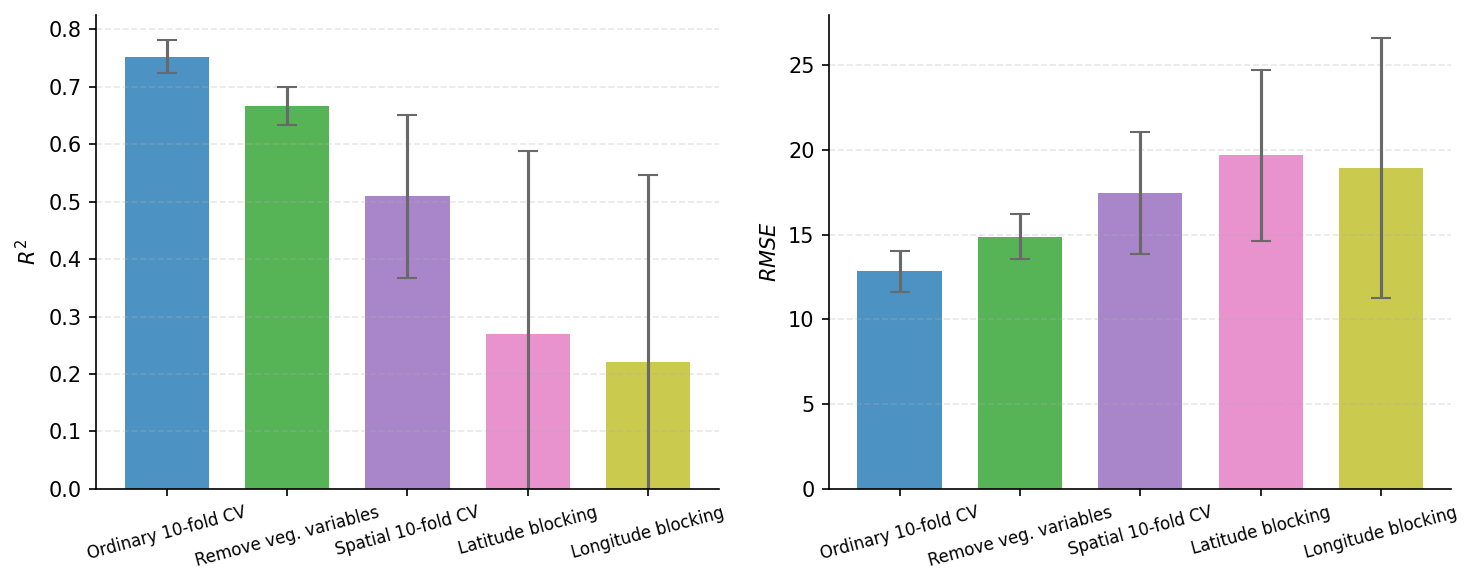

In [8]:
print("Top ordinary CV results:")
display(ordinary_cv_results_df.head())
print("Top spatial CV search results:")
display(spatial_cv_results_df.head())

fig, axs = plt.subplots(1, 2, figsize=(10, 4), dpi=150)
methods = cv_summary_df["method"].tolist()
x = np.arange(len(methods))
bar_colors = plt.get_cmap("tab10")(np.linspace(0, 0.8, len(methods)))

for ax, metric, ylabel in zip(axs, ["R2", "RMSE"], ["$R^2$", "$RMSE$"]):
    means = cv_summary_df[f"{metric}_mean"].values
    stds = cv_summary_df[f"{metric}_std"].values
    ax.bar(x, means, color=bar_colors[:len(methods)], alpha=0.8, width=0.7)
    ax.errorbar(x, means, yerr=stds, fmt="none", capsize=5, color="dimgray")
    ax.set_xticks(x, methods, rotation=15, ha="center", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, None)
    ax.grid(True, axis="y", linestyle="--", alpha=0.3)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show(fig)
plt.close(fig)
